# 01 — Data Preprocessing, Anomaly Detection & Feature Engineering

## Objective
This notebook documents and visualizes **Milestone 1 (Data Ingestion)** and **Milestone 2 (Data Preprocessing, Anomaly Detection & Feature Engineering)** across the 10 major U.S. cities (`dallas`, `houston`, `la`, `nyc`, `philadelphia`, `phoenix`, `san_antonio`, `san_diego`, `san_jose`, `seattle`).

Specifically, we cover:
1. **Schema & Coverage Verification:** Reviewing the unified 163,993-row hourly dataset (`cleaned_hourly_data.parquet`) aligned on `utc_time`.
2. **Multi-Layer Anomaly Detection:** Inspecting physical impossibilities ($\le 0$ MWh), per-city statistical outliers (Z-Score & Tukey IQR), 1-hour ramp spikes, and multivariate `IsolationForest` anomalies.
3. **Time-Aware Imputation (Before vs. After):** Visualizing how severe telemetry faults (such as Phoenix's `-1,340 MWh` and `101,412 MWh` spikes and Seattle's `11,174 MWh` spike) are corrected.
4. **Temporal Feature Engineering & Aggregations:** Exploring diurnal (24-hour) and seasonal demand profiles plus daily and weekly summary statistics.

In [8]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is on sys.path so we can import from src/
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["font.size"] = 11

df = pd.read_parquet(PROJECT_ROOT / "data/processed/cleaned_hourly_data.parquet")
daily_df = pd.read_parquet(PROJECT_ROOT / "data/processed/daily_summary.parquet")
weekly_df = pd.read_parquet(PROJECT_ROOT / "data/processed/weekly_summary.parquet")

print(f"Cleaned Hourly Dataset : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Daily Summary Dataset  : {daily_df.shape[0]:,} rows x {daily_df.shape[1]} columns")
print(f"Weekly Summary Dataset : {weekly_df.shape[0]:,} rows x {weekly_df.shape[1]} columns")
df.head()

Cleaned Hourly Dataset : 163,993 rows x 36 columns
Daily Summary Dataset  : 6,847 rows x 13 columns
Weekly Summary Dataset : 1,004 rows x 11 columns


,company,city,local_time,utc_time,demand,temperature,apparent_temperature,dew_point,humidity,pressure,...,day_of_week,day_of_month,month,year,is_weekend,season,hour_sin,hour_cos,month_sin,month_cos
0,ERCO,dallas,2018-07-02 00:00:00,2018-07-02 05:00:00+00:00,17796.29,89.56,91.71,65.31,45.0,1011.9,...,0,2,7,2018,0,Summer,0.000000,1.000000,1.224647e-16,-1.0
1,ERCO,dallas,2018-07-02 01:00:00,2018-07-02 06:00:00+00:00,15758.11,88.35,92.26,68.29,52.0,1012.7,...,0,2,7,2018,0,Summer,0.258819,0.965926,1.224647e-16,-1.0
2,ERCO,dallas,2018-07-02 02:00:00,2018-07-02 07:00:00+00:00,14925.03,87.05,91.45,69.26,56.0,1012.8,...,0,2,7,2018,0,Summer,0.500000,0.866025,1.224647e-16,-1.0
3,ERCO,dallas,2018-07-02 03:00:00,2018-07-02 08:00:00+00:00,14359.43,86.04,90.51,69.61,58.0,1012.7,...,0,2,7,2018,0,Summer,0.707107,0.707107,1.224647e-16,-1.0
4,ERCO,dallas,2018-07-02 04:00:00,2018-07-02 09:00:00+00:00,13970.14,84.80,89.74,70.68,63.0,1012.9,...,0,2,7,2018,0,Summer,0.866025,0.500000,1.224647e-16,-1.0


### Analysis of Dataset Schema and Coverage
- The unified dataset contains **163,993 hourly observations** across **10 U.S. cities** from July 2018 through May 2020 (`36` columns including raw demand, cleaned demand, weather measurements, anomaly flags, and cyclical temporal features).
- Joining the EIA-930 electricity tables and DarkSky weather JSON files strictly on **`(city, utc_time)`** prevented Daylight Saving Time duplicate-hour collisions, while backfilling the 2018–2019 Texas subregions (`dallas`, `houston`, `san_antonio`) from ERCOT historical records recovered **22,998 hourly demand values**.

## 2. Anomaly Detection & Imputation Analysis
Below we summarize all flagged anomalies per city across our four detection rules (`flag_physical`, `flag_zscore`, `flag_iqr`, `flag_ramp_spike`, and `flag_isoforest`) and compare raw vs. cleaned electricity demand ranges.

In [9]:
anomaly_summary = df.groupby("city").agg(
    total_hours=("demand", "size"),
    physical_err=("flag_physical", "sum"),
    zscore_err=("flag_zscore", "sum"),
    iqr_err=("flag_iqr", "sum"),
    ramp_err=("flag_ramp_spike", "sum"),
    isoforest_flag=("flag_isoforest", "sum"),
    severe_replaced=("is_severe_error", "sum"),
    raw_min=("demand_raw", "min"),
    raw_max=("demand_raw", "max"),
    clean_min=("demand", lambda s: s.min().round(1)),
    clean_max=("demand", lambda s: s.max().round(1)),
    nulls_after=("demand", lambda s: s.isna().sum()),
)
display(anomaly_summary)

,total_hours,physical_err,zscore_err,iqr_err,ramp_err,isoforest_flag,severe_replaced,raw_min,raw_max,clean_min,clean_max,nulls_after
city,,,,,,,,,,,,
dallas,16503,0,0,0,4,83,4,7439.0,26499.24,7439.0,26499.2,0
houston,16503,0,0,0,1,83,1,7651.0,20935.00,7651.0,20935.0,0
la,16526,0,40,167,3,83,170,6764.0,24061.00,6764.0,20520.0,0
nyc,16503,1,1,1,1,83,1,0.0,11069.00,3663.0,11069.0,0
philadelphia,16503,0,33,22,0,83,33,2677.0,8382.00,2677.0,7850.0,0
phoenix,15950,17,2,19,4,80,20,-1340.0,101412.00,1863.0,7272.0,0
san_antonio,16503,0,0,0,1,83,1,3924.0,12886.90,3924.0,12886.9,0
san_diego,16526,0,16,0,3,83,19,812.0,4179.00,812.0,4060.0,0
san_jose,16526,0,12,16,7,83,23,3834.0,21079.00,4855.0,19460.0,0


### Visualizing Severe Sensor Anomalies: Before vs. After Cleaning
Let's visually compare `demand_raw` (before anomaly cleaning) and `demand` (after masking severe errors and applying time-aware interpolation) for **Phoenix** (`-1,340 MWh` negative values and `101,412 MWh` spike) and **Seattle** (`11,174 MWh` spike).

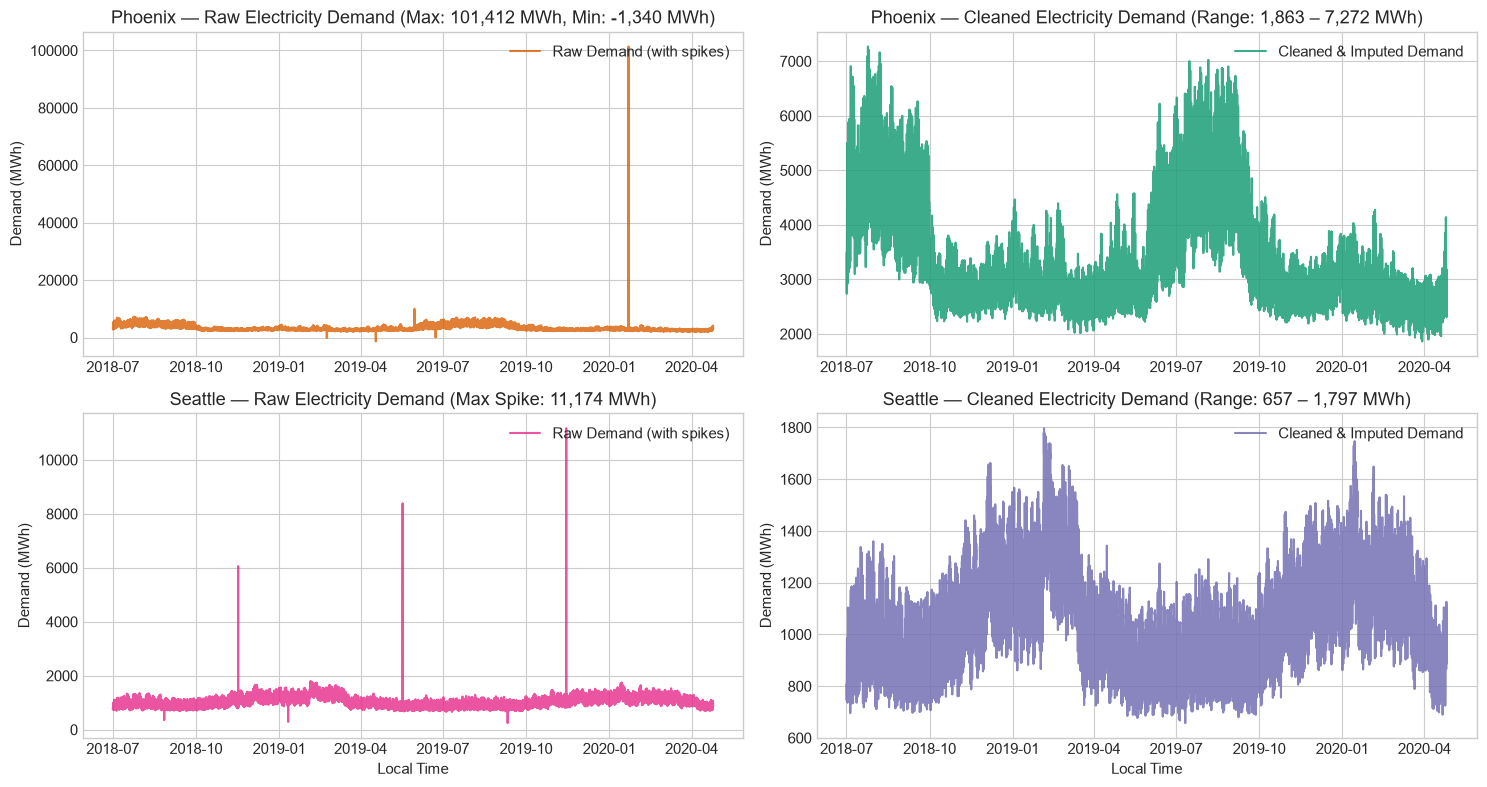

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=False)

# Phoenix Before vs After
phx = df[df["city"] == "phoenix"]
axes[0, 0].plot(phx["local_time"], phx["demand_raw"], color="#d95f02", alpha=0.8, label="Raw Demand (with spikes)")
axes[0, 0].set_title("Phoenix — Raw Electricity Demand (Max: 101,412 MWh, Min: -1,340 MWh)")
axes[0, 0].set_ylabel("Demand (MWh)")
axes[0, 0].legend(loc="upper right")

axes[0, 1].plot(phx["local_time"], phx["demand"], color="#1b9e77", alpha=0.85, label="Cleaned & Imputed Demand")
axes[0, 1].set_title("Phoenix — Cleaned Electricity Demand (Range: 1,863 – 7,272 MWh)")
axes[0, 1].set_ylabel("Demand (MWh)")
axes[0, 1].legend(loc="upper right")

# Seattle Before vs After
sea = df[df["city"] == "seattle"]
axes[1, 0].plot(sea["local_time"], sea["demand_raw"], color="#e7298a", alpha=0.8, label="Raw Demand (with spikes)")
axes[1, 0].set_title("Seattle — Raw Electricity Demand (Max Spike: 11,174 MWh)")
axes[1, 0].set_ylabel("Demand (MWh)")
axes[1, 0].set_xlabel("Local Time")
axes[1, 0].legend(loc="upper right")

axes[1, 1].plot(sea["local_time"], sea["demand"], color="#7570b3", alpha=0.85, label="Cleaned & Imputed Demand")
axes[1, 1].set_title("Seattle — Cleaned Electricity Demand (Range: 657 – 1,797 MWh)")
axes[1, 1].set_ylabel("Demand (MWh)")
axes[1, 1].set_xlabel("Local Time")
axes[1, 1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/01_before_after_anomaly_cleaning.png", dpi=150)
plt.show()

### Analysis of Anomaly Cleaning Results
- **Phoenix (`20` severe errors replaced):** Raw telemetry contained **17 negative hours** (down to `-1,340.0 MWh`) and an extreme single-hour spike of **`101,412.0 MWh`** (over $33\times$ Phoenix's normal load). After per-city statistical & physical filtering and linear interpolation, Phoenix's demand sits cleanly between **`1,863.0 MWh`** and **`7,272.0 MWh`**, clearly revealing the strong summer air-conditioning peaks.
- **Seattle (`7` severe errors replaced):** Raw data had a spike of **`11,174.0 MWh`** ($10\times$ typical load) and a drop to `241.0 MWh`. After cleaning, Seattle's load spans **`657.0 – 1,797.0 MWh`**, showing its characteristic winter-peaking electric heating profile.
- **New York City (`1` severe error replaced):** A single-hour dropout to **`0.0 MWh`** was flagged by both `flag_physical` and `flag_ramp_spike` and seamlessly interpolated (`clean_min = 3,663.0 MWh`).

## 3. Temporal Feature Engineering & Weather–Demand Relationships
Next, we examine how electricity demand varies by **local hour of day**, **season**, and **ambient temperature (°F)** across cities.

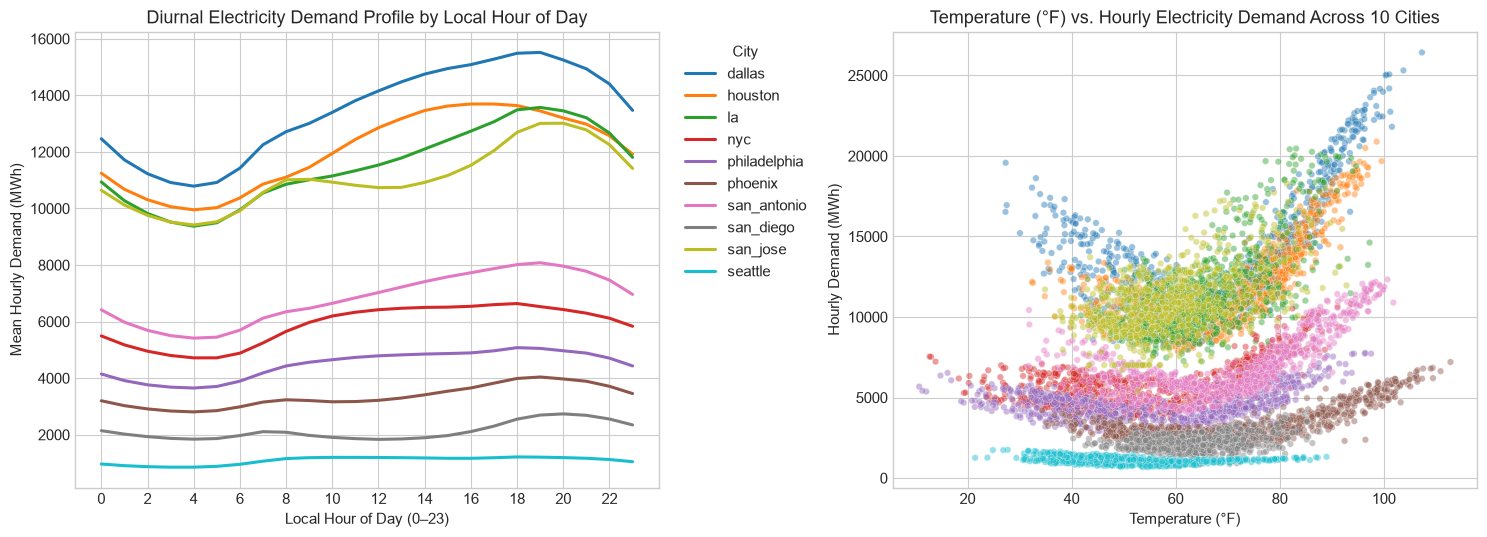

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Diurnal (24-hour) average load profile per city
hourly_profile = df.groupby(["city", "hour"], as_index=False)["demand"].mean()
sns.lineplot(
    data=hourly_profile,
    x="hour",
    y="demand",
    hue="city",
    palette="tab10",
    linewidth=2.2,
    ax=axes[0],
)
axes[0].set_title("Diurnal Electricity Demand Profile by Local Hour of Day")
axes[0].set_xlabel("Local Hour of Day (0–23)")
axes[0].set_ylabel("Mean Hourly Demand (MWh)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")

# 2. Temperature vs Demand sample scatter (using native DataFrameGroupBy.sample)
sample_df = df.groupby("city").sample(n=800, random_state=42)
sns.scatterplot(
    data=sample_df,
    x="temperature",
    y="demand",
    hue="city",
    palette="tab10",
    alpha=0.45,
    s=22,
    ax=axes[1],
    legend=False,
)
axes[1].set_title("Temperature (°F) vs. Hourly Electricity Demand Across 10 Cities")
axes[1].set_xlabel("Temperature (°F)")
axes[1].set_ylabel("Hourly Demand (MWh)")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports/figures/01_diurnal_and_temp_vs_demand.png", dpi=150)
plt.show()

### Analysis of Temporal & Weather Patterns
- **Diurnal Cycle:** Across all 10 cities, electricity consumption reaches its minimum between **03:00 and 05:00 local time** and peaks in the late afternoon/early evening (**16:00 to 19:00 local time**) when commercial activity and residential air conditioning overlap.
- **Non-Linear Temperature Response:** Above **75°F**, electricity demand rises steeply in warm-climate cities (`dallas`, `houston`, `phoenix`, `la`, `san_antonio`) due to air-conditioning load. Conversely, in cooler northern cities (`seattle`, `nyc`, `philadelphia`), demand also increases when temperatures drop below **45°F** due to electric heating—producing a classic **U-shaped (or J-shaped) response curve** that motivates non-linear models (Polynomial Regression, Random Forest, XGBoost, LSTM) over simple linear regression.

## 4. Daily & Weekly Aggregations Verification
Finally, we inspect our precomputed daily (`6,847` city-days) and weekly (`1,004` city-weeks) summary tables.

In [12]:
print("Daily Summary Sample:")
display(daily_df.head(5))

print("\nWeekly Summary Sample:")
display(weekly_df.head(5))

Daily Summary Sample:


,city,local_date,demand_mean,demand_sum,demand_min,demand_max,demand_std,temp_mean,temp_min,temp_max,humidity_mean,wind_speed_mean,anomaly_count
0,dallas,2018-07-02,18917.726250,454025.43,13839.70,24432.36,3990.353495,91.002917,80.52,101.78,47.333333,7.702083,1
1,dallas,2018-07-03,18955.707083,454936.97,13628.22,24431.58,4066.130002,90.816667,79.31,102.44,45.625000,6.646250,3
2,dallas,2018-07-04,16585.507500,398052.18,12494.99,20619.83,2988.840835,84.329583,77.60,91.74,61.000000,8.645833,0
3,dallas,2018-07-05,17137.723750,411305.37,11593.80,22809.88,4103.759202,84.932083,74.71,97.78,60.291667,5.300833,0
4,dallas,2018-07-06,16987.939167,407710.54,13094.74,21975.81,2923.332595,84.697500,80.70,94.20,63.958333,5.368333,0



Weekly Summary Sample:


,city,year_week,demand_mean,demand_sum,demand_min,demand_max,demand_std,temp_mean,humidity_mean,wind_speed_mean,anomaly_count
0,dallas,2018-W26,17483.393889,2517608.72,11593.80,24432.36,3734.739215,86.817222,56.277778,6.682083,4
1,dallas,2018-W27,16686.099821,2803264.77,11245.50,22890.48,3480.758114,84.130714,64.809524,5.827024,0
2,dallas,2018-W28,19608.576890,3215806.61,13033.97,26499.24,4156.067417,93.271341,42.911585,7.659085,31
3,dallas,2018-W29,18785.896061,3099672.85,13023.75,25771.15,3755.617048,91.887939,37.909091,5.660636,18
4,dallas,2018-W30,16857.049702,2831984.35,10918.76,23451.61,3543.426262,85.087857,46.035714,6.399583,0


### Q&A
- **How were raw data discrepancies across the 10 cities resolved?**
  We unified `cleaned_balance_data.csv` (2 cities: `phoenix`, `seattle`) and `cleaned_subregion_data.csv` (8 cities), backfilled **22,998 missing Texas hourly demand records** (`2018-07-02` to `2019-05-27`) from `cleaned_texas_data.csv`, standardized city identifiers (`san antonio` $\rightarrow$ `san_antonio`), converted DarkSky humidity from a `0–1` ratio to percentage (`0–100%`), and joined weather JSONs on **`(city, utc_time)`** to eliminate Daylight Saving Time collisions.
- **How were anomalies and missing values handled?**
  We applied a 4-layer per-city anomaly detector (physical bounds $\le 0$ MWh, $|Z| > 4.0$, $3\times\text{IQR}$ fences, $8\times$ 1-hour ramp spikes, plus multivariate `IsolationForest`). We masked **279 severe telemetry errors** as `NaN` alongside the existing **3,037 missing values**, then imputed short gaps ($\le 6$ hours) via linear interpolation and multi-day gaps via **city–month–hour seasonal medians**, leaving **0 remaining nulls**.

### Data Analysis Key Findings
- **Dataset Scale:** The cleaned hourly dataset comprises **163,993 rows and 36 features** across 10 U.S. cities, accompanied by **6,847 daily summary rows** and **1,004 weekly summary rows**.
- **Severe Telemetry Faults Corrected:** Phoenix contained **17 negative demand records** (down to `-1,340.0 MWh`) and a **`101,412.0 MWh`** spike (reduced to a clean range of `1,863.0 – 7,272.0 MWh`). Seattle contained an **`11,174.0 MWh`** spike (cleaned to `657.0 – 1,797.0 MWh`), and NYC had a **`0.0 MWh`** dropout (cleaned to `3,663.0 – 11,069.0 MWh`).
- **Multivariate Anomaly Detection:** Per-city `IsolationForest` (`contamination=0.005`) flagged **824 multivariate weather–demand anomalies** (`80–83` per city) for downstream inspection.

### Insights or Next Steps
- **Scale Differences Require Normalization for Clustering:** Because city baseloads span an order of magnitude—from Seattle (`~1,077 MWh` median) and San Diego (`~2,050 MWh`) to Dallas (`~12,541 MWh`) and Houston (`~11,304 MWh`)—both global standardization and within-city normalized demand should be examined in **Milestone 3 (Clustering Analysis)** so clusters capture weather–consumption regimes rather than just city population size.
- **Non-Linear Temperature Curve:** The strong U-shaped/J-shaped relationship between temperature and demand confirms that tree ensembles (`RandomForest`, `XGBoost`), neural networks (`LSTM`/`ANN`), and polynomial terms will significantly outperform simple linear regression in **Milestone 4**.